<a href="https://colab.research.google.com/github/YevheniiaMalchenko/ML/blob/main/%D0%9B%D0%A05_%D0%9C%D0%B0%D0%BB%D1%8C%D1%87%D0%B5%D0%BD%D0%BA%D0%BE_3_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Daily Weather Time Series Data - Delhi, India**

https://www.kaggle.com/datasets/yug201/daily-climate-time-series-data-delhi-india?select=kaggel_weather_2013_to_2024.csv

**Тема:** Прогнозування часових рядів на основі кліматичних даних

**Мета роботи:**
Навчитися виконувати аналіз часових рядів, проводити дослідницький аналіз даних (EDA), визначати автокореляційні залежності, будувати моделі прогнозування та оцінювати їхню точність.

**Вихідні дані**

Для виконання роботи використовується датасет Daily Climate Time Series Data (Delhi, India) з платформи Kaggle, який містить щоденні кліматичні показники (температура, вологість, опади тощо) за кілька років.


1. Завантажити датасет з Kaggle.

2. Імпортувати дані у середовище Python (Jupyter Notebook або Google Colab).

3. Ознайомитися зі структурою датасету (head(), info(), describe()).

4. Попередня обробка даних

-Перетворити колонку з датою у формат datetime.

-Відсортувати дані за датою.

-Встановити дату як індекс часового ряду.

-Перевірити наявність пропущених значень та за необхідності обробити їх.

5. Дослідницький аналіз даних (EDA)

-Побудувати графік зміни температури у часі.

-Побудувати ковзне середнє значення температури.

-Побудувати гістограму розподілу температури.

-Побудувати boxplot для виявлення можливих викидів.

-Аналіз автокореляції

Побудувати графік автокореляційної функції (ACF).

Побудувати графік часткової автокореляції (PACF).

-Проаналізувати залежність значень часового ряду від попередніх періодів.

6.Підготовка даних для моделювання

-Розділити дані на тренувальну та тестову вибірки (наприклад, 80% / 20%).

7. Побудувати щонайменше три моделі прогнозування:

-ARIMA (класична статистична модель);

-Prophet (модель прогнозування часових рядів від Meta);

-LSTM (нейронна мережа для послідовних даних).

8. Оцінка моделей
Для кожної моделі обчислити метрики:

-MAE (Mean Absolute Error)

-RMSE (Root Mean Squared Error)

-MAPE (Mean Absolute Percentage Error)

8.Візуалізація результатів

-Побудувати графіки прогнозованих та фактичних значень.

-Побудувати порівняльний графік прогнозів усіх моделей.

-Порівняння моделей

-Створити таблицю з метриками точності.

9.Визначити модель, яка показала найкращий результат.

In [45]:
# Імпортуйте необхідні бібліотеки
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error
from sklearn.preprocessing import MinMaxScaler
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
warnings.filterwarnings("ignore")
plt.style.use("default")


In [5]:
# Завантажте датасет з Kaggle
# Download latest version
import kagglehub

path = kagglehub.dataset_download("yug201/daily-climate-time-series-data-delhi-india")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'daily-climate-time-series-data-delhi-india' dataset.
Path to dataset files: /kaggle/input/daily-climate-time-series-data-delhi-india


In [6]:
# Зчитайте датасет у DataFrame та перегляньте дані
import os
df = pd.read_csv(os.path.join(path, "kaggel_weather_2013_to_2024.csv"))
display(df)

,Unnamed: 0,DATE,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,humidity,precip,...,year-2000,weekofyear,tempmax_humidity,tempmin_humidity,temp_humidity,feelslikemax_humidity,feelslikemin_humidity,feelslike_humidity,temp_range,heat_index
0,0,4/14/2013,37.7,23.1,28.7,35.4,23.1,28.1,39.7,2.0,...,13,15,1496.69,917.07,1139.39,1405.38,917.07,1115.57,14.6,147.178118
1,1,4/15/2013,37.5,21.1,28.6,35.3,21.1,28.0,41.7,0.0,...,13,16,1563.75,879.87,1192.62,1472.01,879.87,1167.60,16.4,151.731061
2,2,4/16/2013,40.1,21.9,31.7,37.5,21.9,30.4,30.7,0.0,...,13,16,1231.07,672.33,973.19,1151.25,672.33,933.28,18.2,118.211133
3,3,4/17/2013,36.4,21.0,29.9,34.0,21.0,28.5,27.4,0.0,...,13,16,997.36,575.40,819.26,931.60,575.40,780.90,15.4,113.320354
4,4,4/18/2013,37.5,21.7,30.6,35.2,21.7,29.2,23.7,0.0,...,13,16,888.75,514.29,725.22,834.24,514.29,692.04,15.8,101.407038
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3552,3552,11/26/2024,25.8,13.6,18.6,25.8,13.6,18.6,65.9,0.0,...,24,48,1700.22,896.24,1225.74,1700.22,896.24,1225.74,12.2,242.171864
3553,3553,11/27/2024,26.2,12.5,18.4,26.2,12.5,18.4,61.0,0.0,...,24,48,1598.20,762.50,1122.40,1598.20,762.50,1122.40,13.7,236.769595
3554,3554,11/28/2024,25.8,11.5,17.9,25.8,11.5,17.9,63.1,0.0,...,24,48,1627.98,725.65,1129.49,1627.98,725.65,1129.49,14.3,243.117035
3555,3555,11/29/2024,25.0,10.6,18.0,25.0,10.6,18.0,60.0,0.0,...,24,48,1500.00,636.00,1080.00,1500.00,636.00,1080.00,14.4,237.638344


Підготовка даних

In [7]:
# Виконайте попередню обробку даних:
# - DATE -> datetime
# - сортування за датою
# - видалення зайвих колонок
# - встановлення DATE як індексу
df["DATE"] = pd.to_datetime(df["DATE"])

df = df.sort_values("DATE")

df = df.drop(columns=["Unnamed: 0"])

df = df.set_index("DATE")

df.head()

,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,humidity,precip,precipprob,precipcover,...,year-2000,weekofyear,tempmax_humidity,tempmin_humidity,temp_humidity,feelslikemax_humidity,feelslikemin_humidity,feelslike_humidity,temp_range,heat_index
DATE,,,,,,,,,,,,,,,,,,,,,
2013-04-14,37.7,23.1,28.7,35.4,23.1,28.1,39.7,2.0,100,4.17,...,13,15,1496.69,917.07,1139.39,1405.38,917.07,1115.57,14.6,147.178118
2013-04-15,37.5,21.1,28.6,35.3,21.1,28.0,41.7,0.0,0,0.00,...,13,16,1563.75,879.87,1192.62,1472.01,879.87,1167.60,16.4,151.731061
2013-04-16,40.1,21.9,31.7,37.5,21.9,30.4,30.7,0.0,0,0.00,...,13,16,1231.07,672.33,973.19,1151.25,672.33,933.28,18.2,118.211133
2013-04-17,36.4,21.0,29.9,34.0,21.0,28.5,27.4,0.0,0,0.00,...,13,16,997.36,575.40,819.26,931.60,575.40,780.90,15.4,113.320354
2013-04-18,37.5,21.7,30.6,35.2,21.7,29.2,23.7,0.0,0,0.00,...,13,16,888.75,514.29,725.22,834.24,514.29,692.04,15.8,101.407038


In [8]:
# Перегляньте інформацію про структуру датасету
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 3557 entries, 2013-04-14 to 2024-11-30
Data columns (total 27 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   tempmax                3557 non-null   float64
 1   tempmin                3557 non-null   float64
 2   temp                   3557 non-null   float64
 3   feelslikemax           3557 non-null   float64
 4   feelslikemin           3557 non-null   float64
 5   feelslike              3557 non-null   float64
 6   humidity               3557 non-null   float64
 7   precip                 3557 non-null   float64
 8   precipprob             3557 non-null   int64  
 9   precipcover            3557 non-null   float64
 10  windspeed              3557 non-null   float64
 11  sealevelpressure       3557 non-null   float64
 12  conditions             3557 non-null   object 
 13  Year                   3557 non-null   int64  
 14  month                  3557 non-null  

In [9]:
# Перевірте наявність пропущених значень
df.isnull().sum()

,0
tempmax,0
tempmin,0
temp,0
feelslikemax,0
feelslikemin,0
feelslike,0
humidity,0
precip,0
precipprob,0
precipcover,0


Графік температури

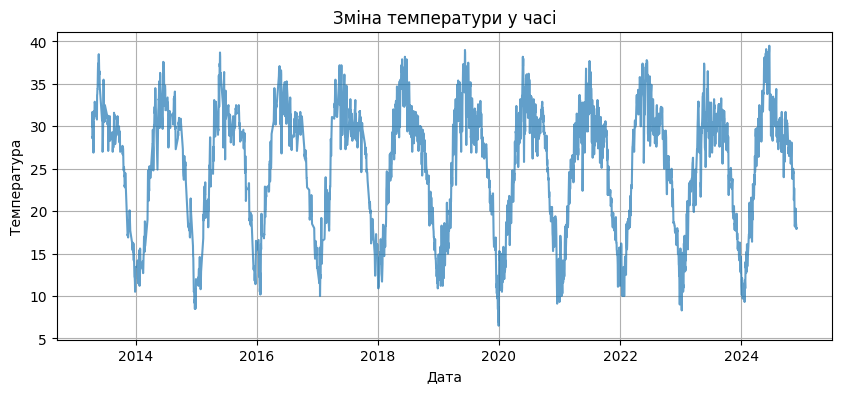

In [10]:
# Побудуйте графік зміни температури у часі
plt.figure(figsize=(10, 4))
plt.plot(df.index, df['temp'], alpha=0.7)
plt.title('Зміна температури у часі')
plt.xlabel('Дата')
plt.ylabel('Температура')
plt.grid(True)
plt.show()

Ковзне середнє

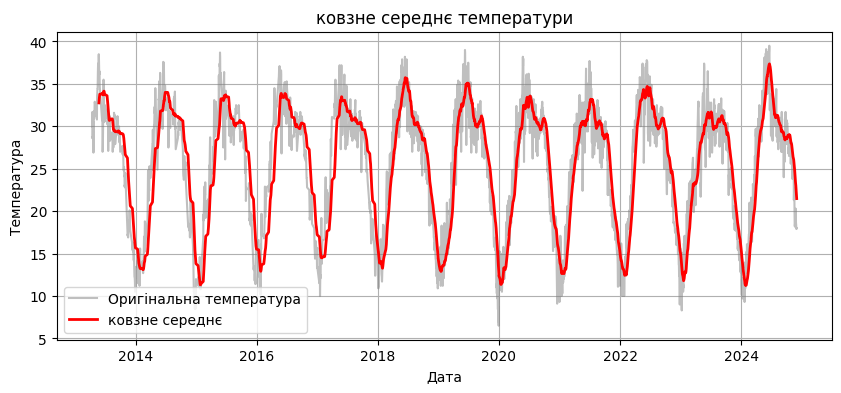

In [11]:
# Обчисліть та візуалізуйте ковзне середнє температури
df['temp_rolling_mean'] = df['temp'].rolling(window=30).mean()
plt.figure(figsize=(10, 4))
plt.plot(df.index, df['temp'], color='gray', alpha=0.5, label='Оригінальна температура')
plt.plot(df.index, df['temp_rolling_mean'], color='red', linewidth=2, label='ковзне середнє')
plt.title('ковзне середнє температури')
plt.xlabel('Дата')
plt.ylabel('Температура')
plt.legend()
plt.grid(True)
plt.show()

Розподіл температури

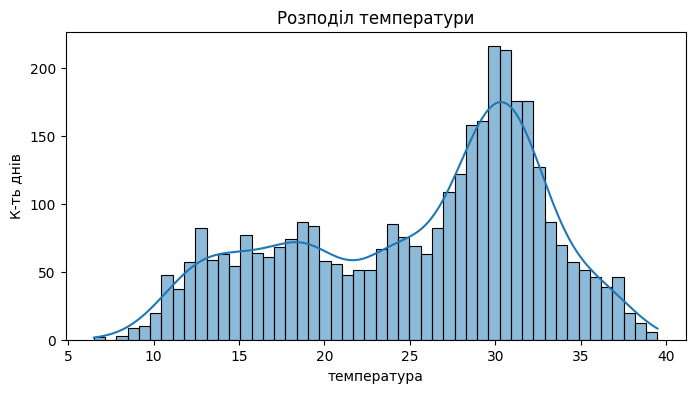

In [12]:
# Побудуйте гістограму розподілу температури
plt.figure(figsize=(8, 4))
sns.histplot(df['temp'], bins=50, kde=True)
plt.title('Розподіл температури')
plt.xlabel('температура')
plt.ylabel('К-ть днів')
plt.show()

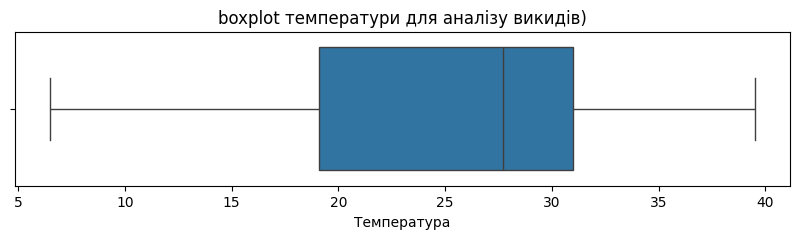

In [13]:
# Побудуйте boxplot температури для аналізу викидів
plt.figure(figsize=(10, 2))
sns.boxplot(x=df['temp'])
plt.title('boxplot температури для аналізу викидів)')
plt.xlabel('Температура')
plt.show()

Аналіз автокореляції
ACF

PACF

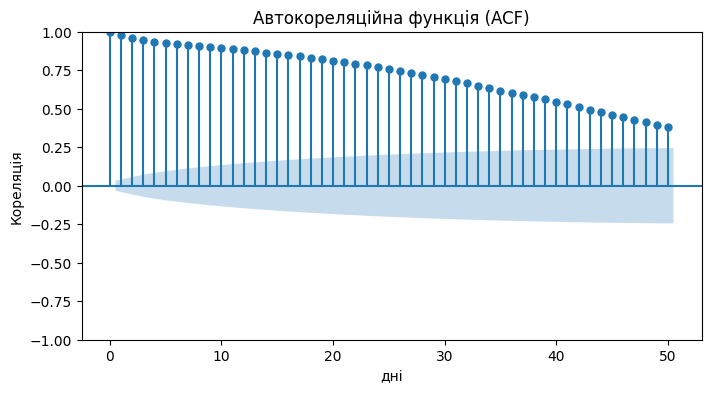

In [14]:
# Побудуйте графік автокореляційної функції (ACF)
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))
plot_acf(df['temp'].dropna(), lags=50, ax=plt.gca())
plt.title('Автокореляційна функція (ACF)')
plt.xlabel('дні')
plt.ylabel('Кореляція')
plt.show()

Автокореляційна функція (ACF) використовується для аналізу залежності значень часового ряду від його попередніх значень. Вона відображає ступінь кореляції між значенням показника у певний момент часу та значеннями цього самого показника у попередні моменти часу, які називаються лагами. Побудова графіка автокореляційної функції дозволяє виявити, чи існує статистично значуща залежність між поточним значенням ряду та його попередніми спостереженнями. На такому графіку по горизонтальній осі відкладаються лаги, тобто кількість часових кроків назад, а по вертикальній — значення коефіцієнта автокореляції. Аналіз графіка ACF дає можливість виявити наявність тренду, сезонності або інших закономірностей у часовому ряді, а також використовується для визначення параметрів статистичних моделей прогнозування, зокрема моделі ARIMA.

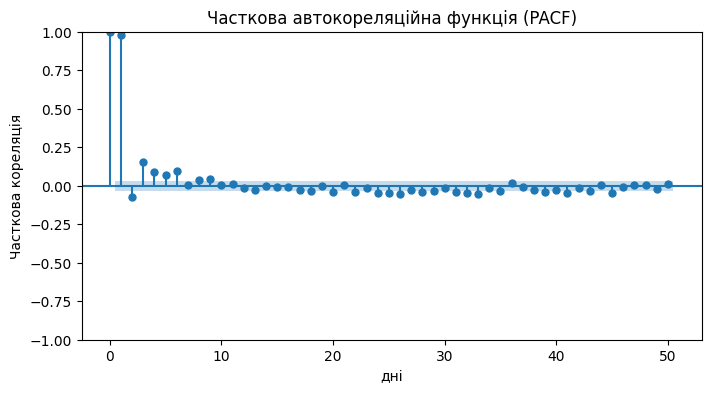

In [15]:
# Побудуйте графік часткової автокореляційної функції (PACF)
plt.figure(figsize=(8, 4))
plot_pacf(df['temp'].dropna(), lags=50, ax=plt.gca(), method='ywm')
plt.title('Часткова автокореляційна функція (PACF)')
plt.xlabel('дні')
plt.ylabel('Часткова кореляція')
plt.show()

Часткова автокореляційна функція (PACF) застосовується для більш точного визначення залежності між значеннями часового ряду. На відміну від звичайної автокореляційної функції, PACF вимірює кореляцію між значенням ряду у певний момент часу та значенням у попередній момент часу з конкретним лагом, усуваючи вплив усіх проміжних лагів. Таким чином, часткова автокореляція показує «чисту» залежність між двома спостереженнями часового ряду. Побудова графіка PACF дозволяє визначити, які саме лаги мають статистично значущий вплив на значення ряду. Це є важливим етапом під час побудови моделей прогнозування часових рядів, оскільки аналіз графіка часткової автокореляції використовується для визначення порядку авторегресійної складової моделі, зокрема параметра
𝑝
p у моделі ARIMA.

In [16]:
# Сформуйте цільовий часовий ряд та розділіть його на train/test у часовому порядку
target = df["temp"].copy()

split_index = int(len(target) * 0.8)

train = target.iloc[:split_index]
test = target.iloc[split_index:]

print("Train size:", len(train))
print("Test size:", len(test))


Train size: 2845
Test size: 712


ARIMA

https://developer.ibm.com/tutorials/awb-arima-models-in-python/

In [17]:
# Побудуйте та навчіть модель ARIMA. Отримайте прогноз для тестової вибірки
train_arima = train.reset_index(drop=True)
arima_model = ARIMA(train_arima, order=(5, 1, 2))
arima_fit = arima_model.fit()

arima_forecast = arima_fit.forecast(steps=len(test))
arima_forecast.index = test.index

print(arima_forecast.head())

DATE
2022-12-20    14.895737
2022-12-21    15.071189
2022-12-22    15.161451
2022-12-23    15.179429
2022-12-24    15.200756
Name: predicted_mean, dtype: float64


In [18]:
# Виведіть статистичний звіт навченої ARIMA-моделі
print(arima_fit.summary())

                               SARIMAX Results                                
Dep. Variable:                   temp   No. Observations:                 2845
Model:                 ARIMA(5, 1, 2)   Log Likelihood               -4969.050
Date:                Mon, 19 Oct 2026   AIC                           9954.101
Time:                        15:19:56   BIC                          10001.724
Sample:                             0   HQIC                          9971.277
                               - 2845                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.1810      0.227      0.799      0.424      -0.263       0.625
ar.L2          0.1094      0.205      0.533      0.594      -0.293       0.511
ar.L3         -0.1108      0.049     -2.242      0.0

сигма 2 : це представляє дисперсію залишкових значень, чим менше, тим краще

логарифмічна правдоподібність : це оцінка максимальної правдоподібності для моделі ARIMA, чим вище, тим краще

aic : міра ступеню відповідності та економності моделі, чим нижче, тим краще

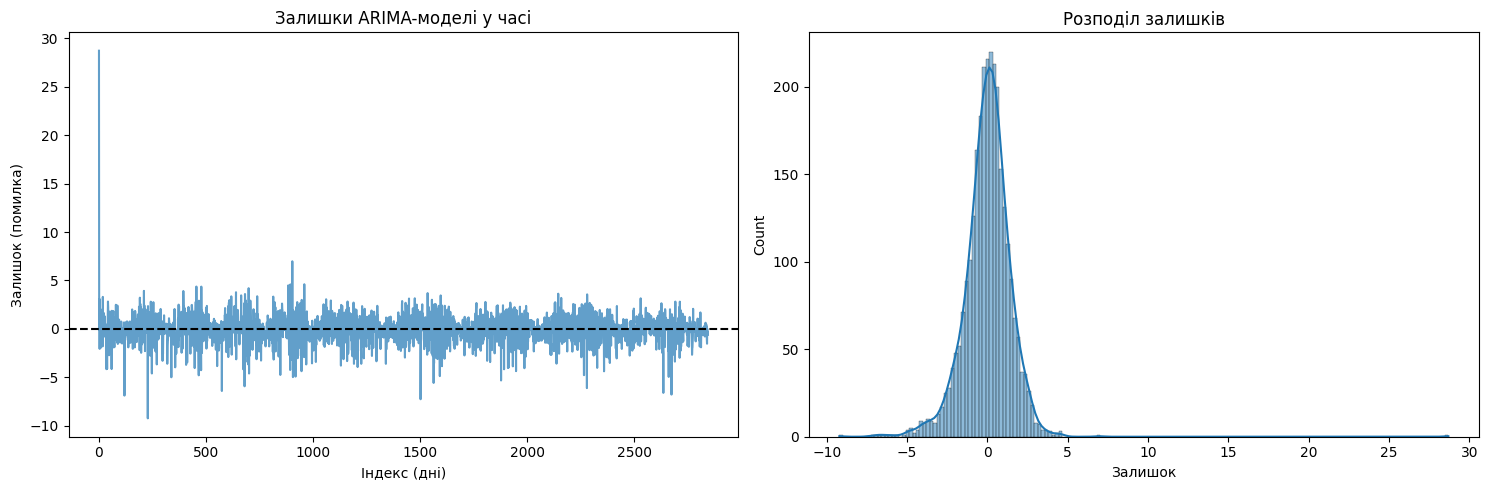

In [19]:
# Проаналізуйте залишки ARIMA-моделі та побудуйте відповідні графіки
residuals = arima_fit.resid

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].plot(residuals, alpha=0.7)
axes[0].set_title('Залишки ARIMA-моделі у часі')
axes[0].set_xlabel('Індекс (дні)')
axes[0].set_ylabel('Залишок (помилка)')
axes[0].axhline(y=0, color='black', linestyle='--')
sns.histplot(residuals, kde=True, ax=axes[1])
axes[1].set_title('Розподіл залишків')
axes[1].set_xlabel('Залишок')
plt.tight_layout()
plt.show()

In [27]:
# Реалізуйте MAPE та обчисліть MAE, RMSE, MAPE для ARIMA
y_true = test.values
y_pred = arima_forecast.values

mae = mean_absolute_error(y_true, y_pred)
rmse = np.sqrt(mean_squared_error(y_true, y_pred))
mape = mean_absolute_percentage_error(y_true, y_pred) * 100

print(f"MAE: {mae:.2f} ")
print(f"RMSE: {rmse:.2f} ")

MAE: 10.93 
RMSE: 12.50 


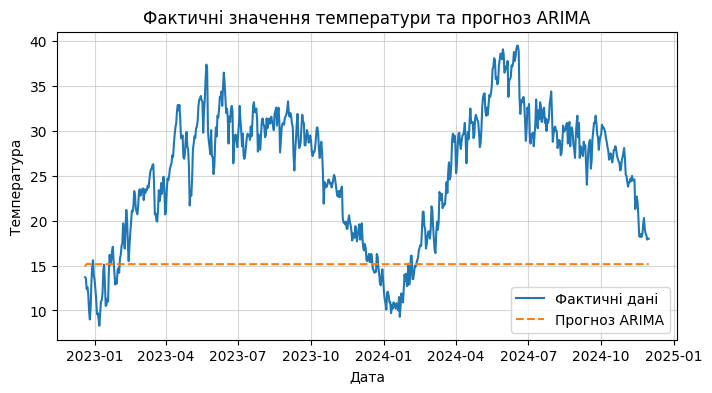

In [30]:
# Візуалізуйте фактичні значення та прогноз ARIMA
plt.figure(figsize=(8, 4))
plt.plot(test.index, test.values, label='Фактичні дані')
plt.plot(test.index, arima_forecast, label='Прогноз ARIMA', linestyle='--')

plt.title('Фактичні значення температури та прогноз ARIMA')
plt.xlabel('Дата')
plt.ylabel('Температура')
plt.legend()
plt.grid(True, alpha=0.5)
plt.show()

PROPHET

https://facebook.github.io/prophet/docs/quick_start.html

In [31]:
!pip install prophet

In [32]:
# Підготуйте дані у форматі, необхідному для Prophet
from prophet import Prophet

df_prophet = pd.DataFrame({
    'ds': train.index,
    'y': train.values
})


In [36]:
# Створіть та навчіть модель Prophet
prophet_model = Prophet(yearly_seasonality=True, daily_seasonality=False, weekly_seasonality=False)
prophet_model.fit(df_prophet)

Прогноз

In [38]:
# Побудуйте прогноз Prophet для тестового періоду
future = pd.DataFrame({'ds': test.index})
forecast_prophet = prophet_model.predict(future)
prophet_predictions = forecast_prophet['yhat'].values

In [39]:
# Обчисліть MAE, RMSE, MAPE для Prophet
y_true = test.values
y_pred_prophet = prophet_predictions
mae_prophet = mean_absolute_error(y_true, y_pred_prophet)
rmse_prophet = np.sqrt(mean_squared_error(y_true, y_pred_prophet))
mape_prophet = mean_absolute_percentage_error(y_true, y_pred_prophet) * 100

print(f"MAE: {mae_prophet:.2f} ")
print(f"RMSE: {rmse_prophet:.2f} ")
print(f"MAPE: {mape_prophet:.2f} ")

MAE: 2.01 
RMSE: 2.60 
MAPE: 9.06 


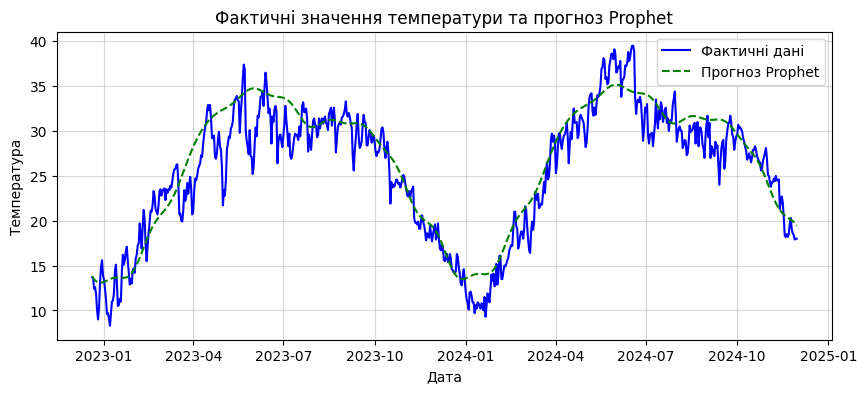

In [41]:
# Візуалізуйте фактичні значення та прогноз Prophet
plt.figure(figsize=(10, 4))
plt.plot(test.index, test.values, label='Фактичні дані', color='blue')
plt.plot(test.index, prophet_predictions, label='Прогноз Prophet', color='green', linestyle='--')
plt.title('Фактичні значення температури та прогноз Prophet')
plt.xlabel('Дата')
plt.ylabel('Температура')
plt.legend()
plt.grid(True, alpha=0.5)
plt.show()

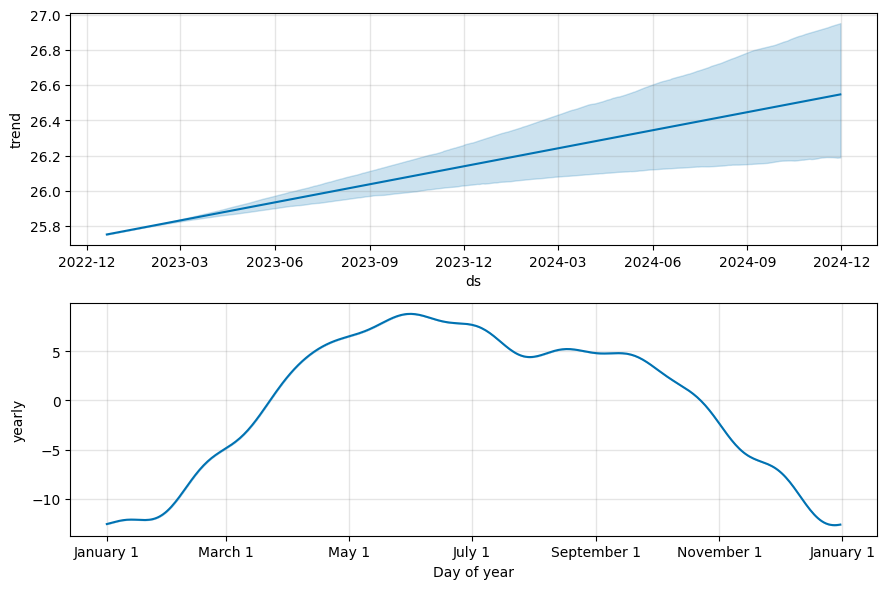

In [42]:
# Побудуйте компоненти моделі Prophet
fig_components = prophet_model.plot_components(forecast_prophet)
plt.show()

ПІДГОТОВКА ДАНИХ ДЛЯ LSTM

In [43]:
# Масштабуйте часовий ряд та сформуйте послідовності для LSTM
all_data = np.concatenate([train.values, test.values]).reshape(-1, 1)

scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(all_data)

def create_sequences(data, seq_length):
    X = []
    y = []
    for i in range(len(data) - seq_length):
        X.append(data[i:i + seq_length])
        y.append(data[i + seq_length])
    return np.array(X), np.array(y)

seq_length = 30
X, y = create_sequences(scaled_data, seq_length)

train_size = len(train)
X_train = X[:train_size - seq_length]
y_train = y[:train_size - seq_length]
X_test = X[train_size - seq_length:]
y_test = y[train_size - seq_length:]
print(f"X_train: {X_train.shape}, X_test: {X_test.shape}")

X_train: (2815, 30, 1), X_test: (712, 30, 1)


In [44]:
# Розділіть послідовності на тренувальну та тестову вибірки без перемішування
print(f"Тренувальні дані: {X_train.shape[0]} послідовностей")
print(f"Тестові дані: {X_test.shape[0]} послідовностей")

Тренувальні дані: 2815 послідовностей
Тестові дані: 712 послідовностей


In [46]:
# Побудуйте архітектуру LSTM-моделі та скомпілюйте її
model_lstm = Sequential()
model_lstm.add(LSTM(units=50, return_sequences=True, input_shape=(X_train.shape[1], 1)))
model_lstm.add(Dropout(0.2))
model_lstm.add(LSTM(units=50, return_sequences=False))
model_lstm.add(Dropout(0.2))
model_lstm.add(Dense(units=1))
model_lstm.compile(optimizer='adam', loss='mean_squared_error')


In [47]:
# Навчіть LSTM-модель
history = model_lstm.fit(X_train, y_train, epochs=30, batch_size=32, validation_data=(X_test, y_test), verbose=1)

Epoch 1/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 5s 28ms/step - loss: 0.0264 - val_loss: 0.0055
Epoch 2/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step - loss: 0.0094 - val_loss: 0.0051
Epoch 3/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - loss: 0.0081 - val_loss: 0.0045
Epoch 4/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 2s 28ms/step - loss: 0.0080 - val_loss: 0.0042
Epoch 5/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 3s 32ms/step - loss: 0.0074 - val_loss: 0.0043
Epoch 6/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - loss: 0.0073 - val_loss: 0.0039
Epoch 7/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - loss: 0.0069 - val_loss: 0.0037
Epoch 8/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - loss: 0.0066 - val_loss: 0.0045
Epoch 9/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 3s 23ms/step - loss: 0.0064 - val_loss: 0.0036
Epoch 10/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 3s 39ms/step - loss: 0.0061 - val_loss: 0.0033
Epoch 11/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 4s 25ms/step - loss: 0.0062 - val_loss: 0.0032
Epoch 12/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 4s 38ms/step - loss: 0.0

In [48]:
# Виведіть структуру LSTM-моделі
model_lstm.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 30, 50)         │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 30, 50)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 50)             │        20,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 91,955 (359.20 KB)

 Trainable params: 30,651 (119.73 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 61,304 (239.47 KB)

In [50]:
# Отримайте прогноз LSTM та виконайте зворотне масштабування
lstm_predictions_scaled = model_lstm.predict(X_test)
lstm_predictions = scaler.inverse_transform(lstm_predictions_scaled)
y_test_actual = scaler.inverse_transform(y_test)

23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step


In [51]:
# Сформуйте часові мітки для тестового прогнозу LSTM
test_dates = test.index[seq_length - 30:]
test_dates = test.index[-(len(lstm_predictions)):]
print(f"К-ть прогнозів: {len(lstm_predictions)}")

К-ть прогнозів: 712


In [52]:
# Обчисліть MAE, RMSE, MAPE для LSTM
mae_lstm = mean_absolute_error(y_test_actual, lstm_predictions)
rmse_lstm = np.sqrt(mean_squared_error(y_test_actual, lstm_predictions))
mape_lstm = mean_absolute_percentage_error(y_test_actual, lstm_predictions) * 100
print(f"MAE: {mae_lstm:.2f}")
print(f"RMSE: {rmse_lstm:.2f} ")
print(f"MAPE: {mape_lstm:.2f} ")

MAE: 1.05
RMSE: 1.36 
MAPE: 4.66 


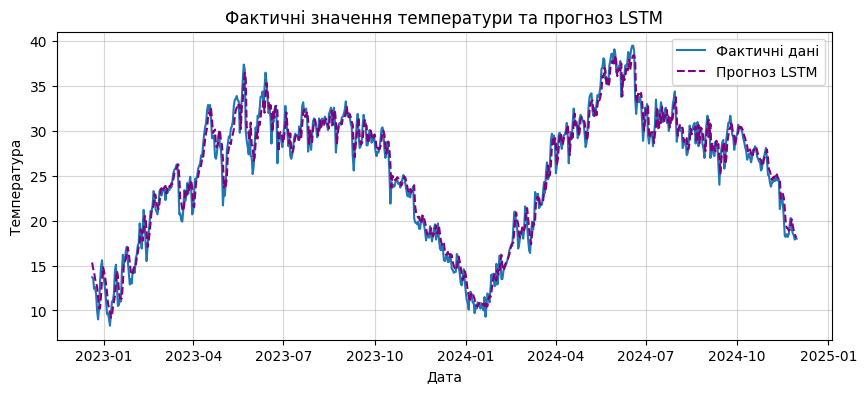

In [53]:
# Візуалізуйте фактичні значення та прогноз LSTM
plt.figure(figsize=(10, 4))
plt.plot(test_dates, y_test_actual, label='Фактичні дані')
plt.plot(test_dates, lstm_predictions, label='Прогноз LSTM', color='purple', linestyle='--')

plt.title('Фактичні значення температури та прогноз LSTM')
plt.xlabel('Дата')
plt.ylabel('Температура')
plt.legend()
plt.grid(True, alpha=0.5)
plt.show()

Порівняння моделей

In [57]:
# Створіть підсумкову таблицю MAE, RMSE, MAPE для ARIMA, Prophet та LSTM
# Порівняйте моделі за отриманими результатами
comparison_data = {
    'Модель': ['ARIMA', 'Prophet', 'LSTM'],
    'MAE': [mae, mae_prophet, mae_lstm],
    'RMSE': [rmse, rmse_prophet, rmse_lstm],
    'MAPE': [mape, mape_prophet, mape_lstm]
}

comparison_df = pd.DataFrame(comparison_data).round(2)
print("Підсумквое порівняння моделей")
display(comparison_df)
best_model = comparison_df.loc[comparison_df['MAE'].idxmin(), 'Модель']

print(f"Найкращий результат показала модель: {best_model}")

Підсумквое порівняння моделей


,Модель,MAE,RMSE,MAPE
0,ARIMA,10.93,12.50,39.59
1,Prophet,2.01,2.60,9.06
2,LSTM,1.05,1.36,4.66


Найкращий результат показала модель: LSTM


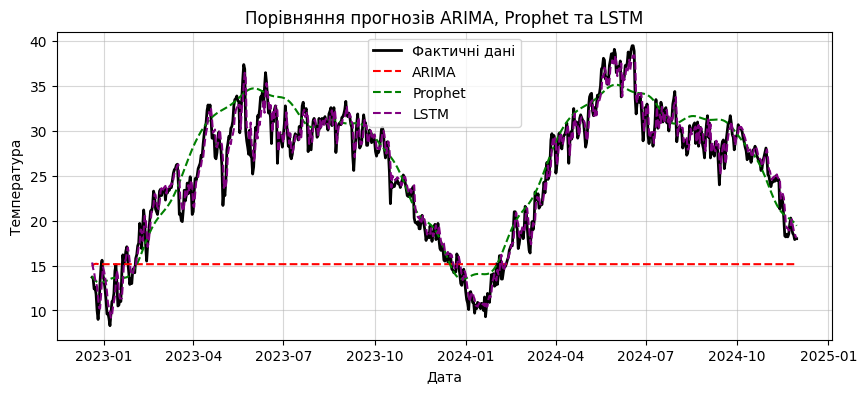

In [59]:
# Порівняльний графік прогнозів усіх моделей
plt.figure(figsize=(10, 4))
plt.plot(test.index, test.values, label='Фактичні дані', color='black', linewidth=2)
plt.plot(test.index, arima_forecast, label='ARIMA', linestyle='--', color='red')
plt.plot(test.index, prophet_predictions, label='Prophet', linestyle='--', color='green')
plt.plot(test_dates, lstm_predictions, label='LSTM', linestyle='--', color='purple')
plt.title('Порівняння прогнозів ARIMA, Prophet та LSTM')
plt.xlabel('Дата')
plt.ylabel('Температура')
plt.legend()
plt.grid(True, alpha=0.5)
plt.show()

## Висновок

Сформулюйте висновок за результатами роботи: коротко охарактеризуйте виконаний аналіз, порівняйте моделі ARIMA, Prophet та LSTM за метриками MAE, RMSE і MAPE та зазначте, яка модель продемонструвала найкращу якість прогнозування.


У роботі було порівняно три моделі прогнозування часових рядів: ARIMA, Prophet та LSTM.

ARIMA показала найгірший результат (MAE ≈ 10.93), оскільки не враховує сезонність і видала майже сталий прогноз.

Prophet впорався значно краще (MAE ≈ 2.01), автоматично розпізнавши річні цикли температури.

LSTM продемонструвала найкращий результат (MAE ≈ 1.05, MAPE ≈ 4.66%), точно відтворивши як сезонні тренди, так і щоденні коливання.


Найкращу якість прогнозування показала нейромережа LSTM, яка виявилася найбільш ефективною для цього типу даних